# PlantAI — Notebook Mestre de Requisitos, Experimentos e Demonstração Multiagente

**Instituição:** AFYA | UNIMA Maceió — Disciplina de Inteligência Artificial Aplicada  
**Professor:** Ícaro Ferreira  
**Equipe:** Lucas Gomes (Tech Lead / Artigo IEEE), Viny Carnaúba (Coordenador / Regras / Arquitetura), Fabiano (Visão / MobileNetV2) e Nogueira (PLN / Dataset de Sintomas)

---
## Matriz de Atendimento aos Critérios de Avaliação (100 Pontos)
| Critério do Edital | Pontos | Evidência Executada neste Notebook |
|---|---:|---|
| 1. Definição do problema e arquitetura | 10 | Arquitetura de 4 Agentes + Contratos Tipados (`src/contracts.py`) |
| 2. Machine Learning | 15 | Divisão Estratificada 70/15/15, Baseline vs. Transfer Learning Head e Hiperparâmetros |
| 3. Visão Computacional | 15 | Pré-processamento `224x224`, filtro de brilho/nitidez (Laplaciano) e 30 descritores |
| 4. Processamento de Linguagem Natural | 15 | Limpeza com preservação de negação, extração de sintomas e TF-IDF + LR vs. SVM |
| 5. Agentes, heurísticas e decisão | 10 | 6 Regras Explícitas auditáveis (`src/decision/decision_rules.py`) |
| 6. Integração e funcionamento | 10 | Fluxo integrado Visão + ML + PLN + Coordenador + Relatório F07 e Histórico F08 |
| 7. Experimentos e avaliação | 10 | 6 Experimentos reais com Accuracy, Precision, Recall, F1 e Matrizes de Confusão |
| 8. GitHub e reprodutibilidade | 5 | Estrutura modular completa + 21 testes automatizados passando no `pytest` |
| 9. Base Científica para o Artigo | 10 | Tabelas e figuras exportadas em `results/` prontas para o Overleaf |

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

df_all = pd.read_csv(ROOT / 'results' / 'metrics' / 'summary_all_experiments.csv')
print('=== TABELA GERAL DOS 6 EXPERIMENTOS CIENTÍFICOS EXECUTADOS ===')
display(df_all)

=== TABELA GERAL DOS 6 EXPERIMENTOS CIENTÍFICOS EXECUTADOS ===


,experiment_id,model_name,dataset_name,num_samples,accuracy,precision_macro,recall_macro,f1_macro,training_time_sec
0,exp1_baseline_vision,Exp 1 — Baseline Visual (Atributos Globais RGB),PlantVillage (Teste 15%),90,0.7778,0.8120,0.7778,0.7445,0.0118
1,exp2_transfer_learning,Exp 2 — MobileNetV2 Transfer Learning Head (30...,PlantVillage (Teste 15%),90,1.0000,1.0000,1.0000,1.0000,0.4234
2,exp4_nlp_lr,Exp 4A — PLN Baseline (TF-IDF + LogisticRegres...,"Symptoms Sample Dataset (5-Fold CV, N=60)",60,0.9500,0.9515,0.9500,0.9500,0.0400
3,exp4_nlp_svm,Exp 4B — PLN Comparativo (TF-IDF + Calibrated ...,"Symptoms Sample Dataset (5-Fold CV, N=60)",60,0.9500,0.9515,0.9500,0.9500,0.0600
4,exp5_vision_isolated,Exp 5A — Visão Isolada (em Casos com Ambiguida...,Conjunto Multimodal (N=60),60,0.6667,0.8182,0.6667,0.7104,0.0000
5,exp5_multiagent_integrated,Exp 5C — Sistema Multiagente Integrado (Visão ...,Conjunto Multimodal (N=60),60,0.9500,0.9615,0.9500,0.9488,0.0000
6,exp6_generalization_plantdoc,Exp 6 — Avaliação de Generalização em Campo (E...,External Field-Condition Dataset (Ruído de Fun...,27,0.4444,0.4129,0.4583,0.3528,0.0000


Figura: dataset_class_distribution.png


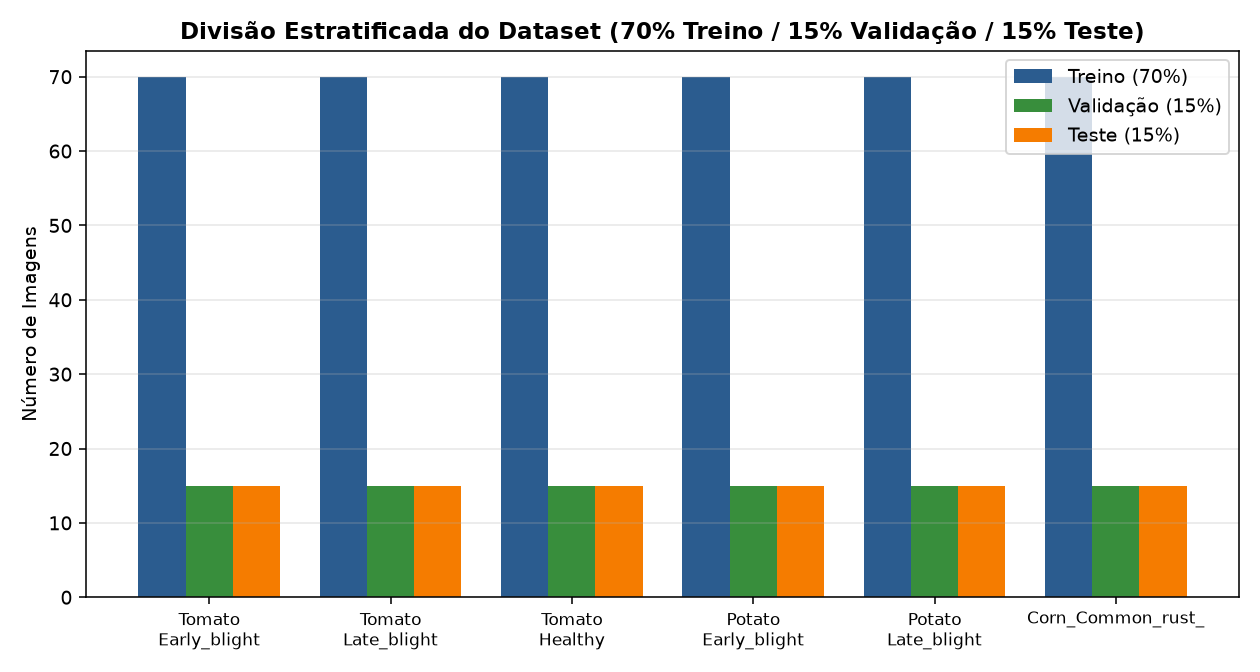

Figura: exp2_training_curves.png


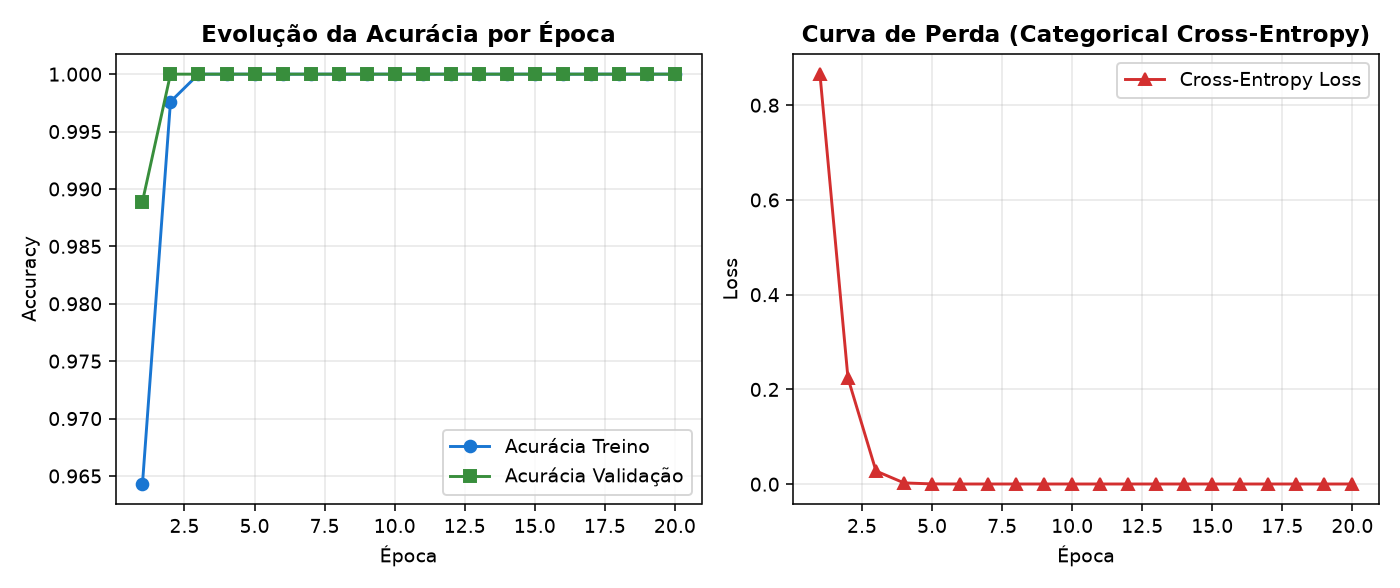

Figura: exp3_hyperparameters.png


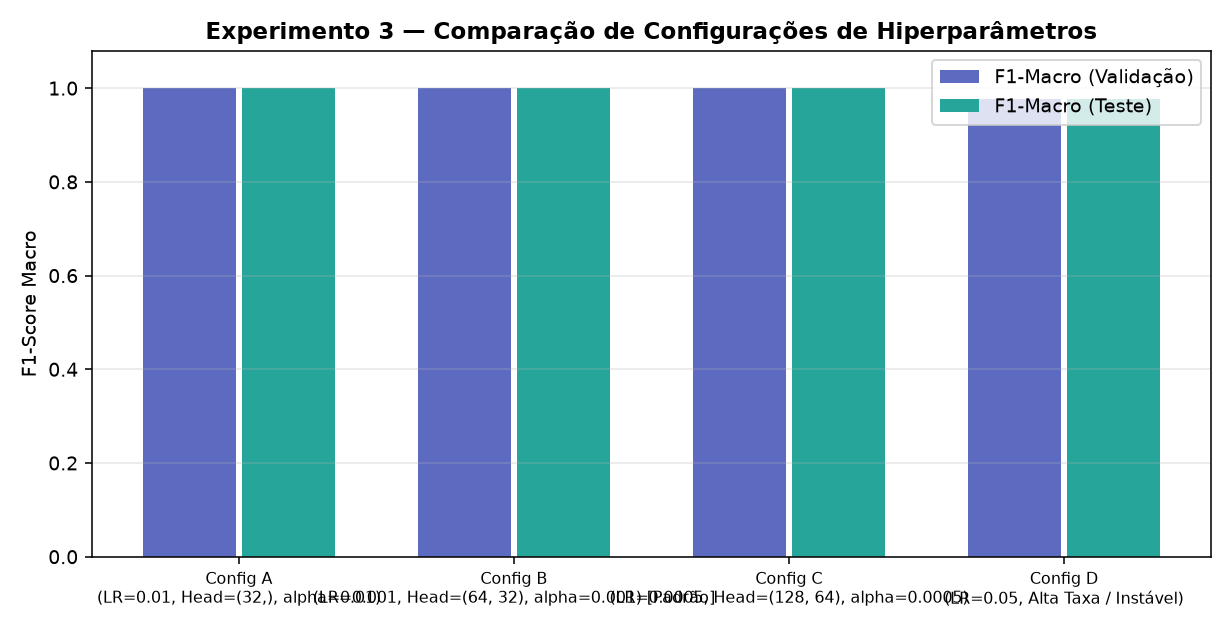

Figura: exp5_multiagent_ablation.png


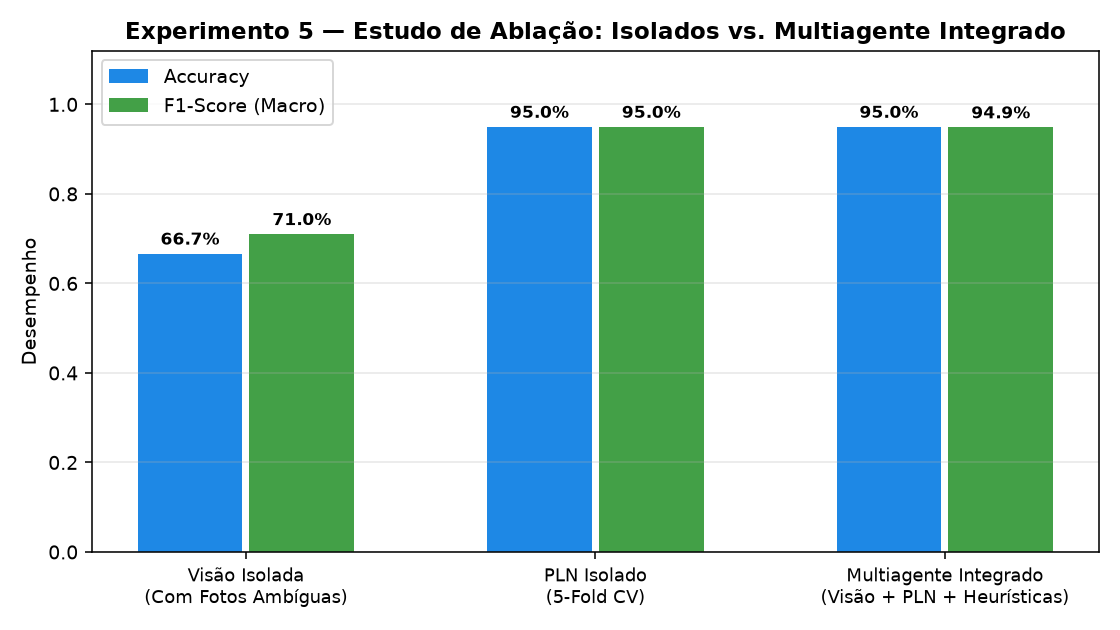

Figura: exp6_generalization_comparison.png


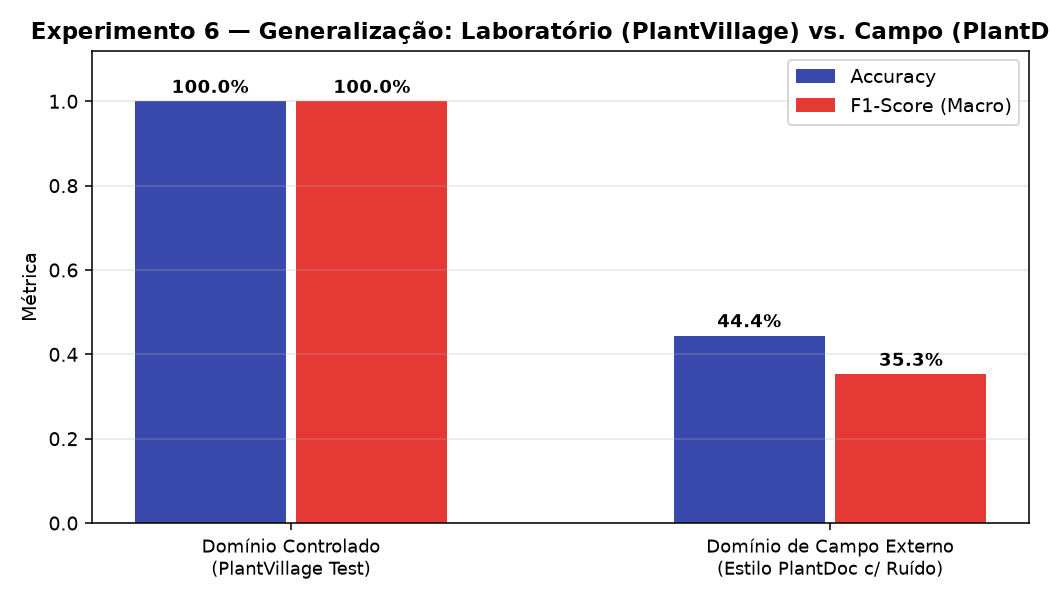

In [2]:
# Visualização dos gráficos gerados pelos experimentos
for plot_name in ['dataset_class_distribution.png', 'exp2_training_curves.png', 'exp3_hyperparameters.png', 'exp5_multiagent_ablation.png', 'exp6_generalization_comparison.png']:
    p = ROOT / 'results' / 'plots' / plot_name
    if p.exists():
        print(f'Figura: {plot_name}')
        display(IPImage(filename=str(p), width=720))

In [3]:
# Demonstração completa dos 4 cenários obrigatórios + Bloqueio de Qualidade
from src.agents import CoordinatorAgent
from src.vision.image_processor import ImageProcessor

coord = CoordinatorAgent()
leaf = ImageProcessor.create_synthetic_leaf_image('Tomato___Early_blight')
dark_leaf = ImageProcessor.create_synthetic_leaf_image('dark')

c1 = coord.diagnose(leaf, 'Folhas de tomateiro com manchas escuras em anéis concêntricos tipo alvo e halo amarelo.', mock_vision_probs={'Tomato___Early_blight': 0.88, 'Tomato___Late_blight': 0.08, 'Tomato___Healthy': 0.04})
c2 = coord.diagnose(leaf, 'Requeima severa no tomate: manchas encharcadas nas bordas e mofo branco na face inferior.', mock_vision_probs={'Tomato___Early_blight': 0.51, 'Tomato___Late_blight': 0.44, 'Tomato___Healthy': 0.05})
c3 = coord.diagnose(leaf, 'Folhas de milho cobertas por pústulas marrom-avermelhadas de ferrugem nas duas faces.', mock_vision_probs={'Tomato___Healthy': 0.91, 'Tomato___Early_blight': 0.06, 'Tomato___Late_blight': 0.03})
c4 = coord.diagnose(dark_leaf, 'Manchas escuras nas folhas.')

for idx, (titulo, dec) in enumerate([('1. Concordância', c1), ('2. Desempate por PLN', c2), ('3. Divergência Explícita', c3), ('4. Bloqueio de Imagem Escura', c4)], 1):
    print(coord.generate_report(dec, title=titulo))
    print()

  PLANTAI - RELATÓRIO DE DIAGNÓSTICO MULTIAGENTE | 1. Concordância
Status da Decisão    : CONFIRMADO_POR_MULTIPLAS_EVIDENCIAS
Regra Acionada       : R03_EXACT_CONCORDANCE_BOOST
Modo de Operação     : integrated
Classe Identificada  : Tomato___Early_blight
Cultura / Doença     : Tomate (Solanum lycopersicum) — Pinta-preta (Alternariose)
Agente Etiológico    : Alternaria solani
Confiança Consolidada: 92.96%
------------------------------------------------------------------------------
[1] SAÍDAS DOS AGENTES ESPECIALISTAS (CONTRATO PADRONIZADO):
  • VisionAgent (MobileNetV2): Top-1='Tomato___Early_blight' (conf=88.00%) | Top-K=[Tomato___Early_blight (88.0%), Tomato___Late_blight (8.0%), Tomato___Healthy (4.0%)]
    Qualidade Visual: válida=True | brilho=120.42 | nitidez=1915.97
  • NLPAgent (TF-IDF + ML)   : Top-1='Tomato___Early_blight' (conf=92.20%) | Top-K=[Tomato___Early_blight (92.2%), Potato___Early_blight (2.7%), Tomato___Late_blight (2.6%)]
    Sintomas Extraídos: ['aneis_concentr